# Modul 379 · Quartiera AG: Was stört unsere Gäste wirklich?

Dieses Notebook ist **eigenständig**: Es braucht nur diese eine Datei. Es lädt die Daten selbst, fragt das KI-Werkzeug **JEV** (TypeSafe) ab und erstellt alle Auswertungen und die 3 Grafiken für die Geschäftsleitung.

| # | Entscheid | Frage an die Daten | Kennzahl |
|---|---|---|---|
| 1 | Wohin fliessen CHF 500'000 Coaching-Budget? | Welche Themen nennen unzufriedene Gäste (1–2 Sterne) am häufigsten? | Anteil pro Thema, mit Bandbreite |
| 2 | Fragen wir die richtigen Teilnoten ab? | Welche Themen kosten Sterne, obwohl die 5 Teilnoten sie nicht abbilden? | Zusätzlicher Sterne-Abzug (Regression) |
| 3 | Texte automatisch auswerten? | Wie gut erkennt JEV Beschwerden, und wo irrt es sich? | Trefferquote, Präzision, Stabilität, Vergleich mit Stichwörtern |

**Vorgehen (hybride Pipeline):** Code bereitet vor → KI interpretiert → Code prüft und rechnet → Mensch entscheidet.

### So benutzt ihr das Notebook
1. Die Zellen der Reihe nach ausführen (*Run All*).
2. Beim JEV-Schritt wird der **API-Key** abgefragt (verdeckte Eingabe). Er wird nirgends gespeichert.
3. Die JEV-Antworten werden in `jev_results.csv` zwischengespeichert. Beim nächsten Durchlauf kostet es nichts mehr.

Dateien, die das Notebook im gleichen Ordner erzeugt: `tripadvisor.parquet` (ca. 220 MB, Download), `jev_results.csv`, `jev_rerun_200.csv`, `grafik1–3.png`, `eure_kontrolle.csv`.

## 0 · Setup

In [1]:
# Einmalig nötig (danach kann die Zeile auskommentiert bleiben):
# %pip install typesafe-sdk pandas pyarrow matplotlib statsmodels

import os, re, csv, time, asyncio, getpass, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from IPython.display import display

warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 25)

N_SAMPLE  = 5000                      # Vorgabe Lehrperson: die ersten 5'000 Sätze
DATA_FILE = "tripadvisor.parquet"     # oder die Datei der Lehrperson (.parquet oder .csv)
DATA_URL  = "https://huggingface.co/datasets/jniimi/tripadvisor-review-rating/resolve/main/data/train-00000-of-00001.parquet"
JEV_FILE  = "jev_results.csv"

## 1 · Daten laden und kennenlernen (HZ 1)

Quelle: *TripAdvisor Review Rating* (Hugging Face `jniimi/tripadvisor-review-rating`, Lizenz Apache-2.0, ursprünglich Li et al. 2013). 201'295 englische Hotelbewertungen aus dem Jahr 2012.

| Spalte | Art | Bedeutung |
|---|---|---|
| `overall` | quantitativ, ordinal (1–5) | Gesamtnote |
| `cleanliness`, `value`, `location`, `rooms`, `sleep_quality` | quantitativ, ordinal (1–5) | die 5 Teilnoten |
| `title`, `text` | **qualitativ** (Freitext) | Nur hier steht, *warum* ein Gast unzufrieden ist |
| `user_id` | Kennung (Pseudonym) | Personendatum → wird entfernt |
| `hotel_id` | Kennung | wird geprüft |
| `post_date`, `stay_year`, `char`, `lang`, `freq` | Metadaten | Datum, Jahr, Länge, Sprache |

In [2]:
if not os.path.exists(DATA_FILE):
    print("Lade Datensatz von Hugging Face (ca. 220 MB) ...")
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

full = pd.read_parquet(DATA_FILE) if DATA_FILE.endswith(".parquet") else pd.read_csv(DATA_FILE)
full["review_id"] = range(len(full))      # Zeilennummer = stabile ID
print(full.shape)
full.dtypes

(201295, 17)


hotel_id                  int64
user_id                     str
title                       str
text                        str
overall                 float64
cleanliness             float64
value                   float64
location                float64
rooms                   float64
sleep_quality           float64
stay_year                 int64
post_date        datetime64[ns]
freq                      int64
review                      str
char                      int64
lang                        str
review_id                 int64
dtype: object

In [3]:
SUBS  = ["cleanliness", "value", "location", "rooms", "sleep_quality"]
SUB_DE = {"cleanliness": "Sauberkeit", "value": "Preis-Leistung", "location": "Lage",
          "rooms": "Zimmer", "sleep_quality": "Schlaf"}

vergleich = pd.DataFrame({
    "alle Bewertungen": full.overall.value_counts(normalize=True).sort_index(),
    f"erste {N_SAMPLE}": full.head(N_SAMPLE).overall.value_counts(normalize=True).sort_index(),
}).mul(100).round(1)
print("Verteilung der Sterne in % (ist die Stichprobe verzerrt?)")
vergleich

Verteilung der Sterne in % (ist die Stichprobe verzerrt?)


,alle Bewertungen,erste 5000
overall,,
1.0,4.0,4.1
2.0,5.4,5.7
3.0,14.0,13.8
4.0,33.6,33.7
5.0,43.0,42.7


➜ Die ersten 5'000 Zeilen haben praktisch dieselbe Sterneverteilung wie der ganze Datensatz. Die Vorgabe «die ersten 5'000» ist deshalb vertretbar.

## 2 · Datenqualität (HZ 2)

Wir prüfen fehlende Werte, Duplikate, unmögliche Werte und Ausreisser und halten jeden Entscheid in einem **Bereinigungsprotokoll** fest.

In [4]:
print("Eindeutige hotel_id:", full.hotel_id.nunique(), "bei", len(full), "Zeilen")
print("Doppelte Texte im ganzen Datensatz:", int(full.duplicated(["text"]).sum()))
print("Textlänge (Zeichen):"); print(full.char.describe().round(0))

Eindeutige hotel_id: 201295 bei 201295 Zeilen


Doppelte Texte im ganzen Datensatz: 40
Textlänge (Zeichen):
count    201295.0
mean        839.0
std         679.0
min          57.0
25%         412.0
50%         657.0
75%        1033.0
max       22418.0
Name: char, dtype: float64


⚠️ **`hotel_id` ist pro Zeile eindeutig.** Es ist also keine echte Hotel-ID. Damit lässt sich nicht testen, ob Beschwerden «beim richtigen Hotel landen» (wichtig für Entscheid 3).

In [5]:
s = full.head(N_SAMPLE).copy()
log = []
log.append(("Fehlende Werte", int(s.isna().sum().sum()), "keine Aktion nötig"))
d = s.duplicated(["text"]);                         log.append(("Doppelter Text", int(d.sum()), "entfernen (erste behalten)")); s = s[~d]
bad = ~s[["overall"] + SUBS].isin([1, 2, 3, 4, 5]).all(axis=1)
log.append(("Note ausserhalb 1–5", int(bad.sum()), "entfernen"));            s = s[~bad]
log.append(("Text < 50 Zeichen", int((s.text.str.len() < 50).sum()), "behalten, markieren"))
log.append(("Sehr lange Texte > 5'000 Zeichen", int((s.text.str.len() > 5000).sum()), "behalten (JEV verarbeitet bis 32k Tokens)"))
protokoll = pd.DataFrame(log, columns=["Problem", "Anzahl Zeilen", "Entscheid"])
protokoll

,Problem,Anzahl Zeilen,Entscheid
0,Fehlende Werte,0,keine Aktion nötig
1,Doppelter Text,0,entfernen (erste behalten)
2,Note ausserhalb 1–5,0,entfernen
3,Text < 50 Zeichen,0,"behalten, markieren"
4,Sehr lange Texte > 5'000 Zeichen,4,behalten (JEV verarbeitet bis 32k Tokens)


## 3 · Datenschutz vor dem Versand (HZ 4)

- `user_id` und `hotel_id` werden **nicht** an JEV geschickt.
- Namen nach Anrede oder «named …», E-Mail-Adressen und Telefonnummern werden maskiert.
- **Grenze:** Vornamen ohne Anrede (z.B. «thanks to Maria») erkennt die Regel nicht. Darum verwenden wir im Report **keine Zitate** ohne Kontrolle von Hand.

In [6]:
_TITLE = re.compile(r"\b(Mr|Mrs|Ms|Miss|Dr|Mister)\.?\s+[A-Z][a-z]+(\s+[A-Z][a-z]+)?")
_NAMED = re.compile(r"\b(named|called|name is|name was)\s+[A-Z][a-z]+(\s+[A-Z][a-z]+)?")
_EMAIL = re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+")
_PHONE = re.compile(r"\+?\d[\d\s().-]{7,}\d")

def mask(text):
    text = _EMAIL.sub("[EMAIL]", text)
    text = _PHONE.sub("[TEL]", text)
    text = _TITLE.sub(lambda m: m.group(1) + " [NAME]", text)
    text = _NAMED.sub(lambda m: m.group(1) + " [NAME]", text)
    return text

print(mask("The night manager Mr Smith was rude, call +1 312 555 0199 or smith@hotel.com"))

s["title_masked"] = s.title.map(mask)
s["text_masked"]  = s.text.map(mask)
s = s.drop(columns=["user_id", "hotel_id"])          # Personendaten / unbrauchbare Kennung entfernen
print("Bewertungen mit Maskierung:", int((s.text_masked != s.text).sum()))
print("Stichprobe:", len(s), "Bewertungen")

The night manager Mr [NAME] was rude, call [TEL] or [EMAIL]


Bewertungen mit Maskierung: 77
Stichprobe: 5000 Bewertungen


## 4 · Vom Text zur Zahl: das Codebuch für JEV (HZ 1 + 2)

JEV beantwortet **Noul-Fragen**: Pro Aussage gibt es eine Wahrscheinlichkeit von 0 bis 1, dass sie stimmt. Pro Bewertung stellen wir 17 Fragen in **einer** Anfrage.

Regeln aus der JEV-Doku:
- Fragen eng und wörtlich formulieren.
- Zählen und Rechnen macht der Code.
- Schwellen: **≥ 0.7 = ja, ≤ 0.3 = nein**, dazwischen = **unsicher**. Für Zählungen gilt 0.5, die Unsicherheit zeigen wir als Bandbreite.

«Teilnote» = welche der 5 heutigen Teilnoten das Thema abdeckt (`None` = wird nicht abgefragt).

In [7]:
THEMES = {   # Code: (Thema, Teilnote, Frage an JEV)
    "complaint":         ("Beschwerde (irgendeine)", None, "The guest describes at least one problem, complaint or disappointment with the hotel or the stay."),
    "staff_service":     ("Personal & Service", None, "The guest complains about hotel staff or service: rude, unfriendly, unhelpful, incompetent or slow staff, or poor customer service."),
    "checkin_booking":   ("Check-in, Reservation & Rechnung", None, "The guest complains about check-in, check-out, the reservation or billing: long waits, room not ready, booking errors, wrong room type, or being charged incorrectly."),
    "cleanliness":       ("Sauberkeit & Geruch", "cleanliness", "The guest complains that the room, bathroom, bed or hotel was dirty, smelly or not cleaned properly."),
    "pests":             ("Ungeziefer (Bettwanzen etc.)", "cleanliness", "The guest reports bed bugs, cockroaches, mice or other pests."),
    "room_condition":    ("Zustand: alt, abgenutzt, defekt", "rooms", "The guest complains that the room or hotel is old, worn, outdated, run-down or in need of renovation, or that things in the room were broken."),
    "room_size":         ("Zimmer zu klein", "rooms", "The guest complains that the room was too small or cramped."),
    "bathroom_plumbing": ("Bad, Dusche, Wasser", "rooms", "The guest complains about the bathroom, shower, water pressure, hot water or plumbing."),
    "ac_heating":        ("Klimaanlage & Heizung", "rooms", "The guest complains about air conditioning, heating, or the room being too hot or too cold."),
    "noise":             ("Lärm", "sleep_quality", "The guest complains about noise: from other guests, the street, construction, thin walls or hotel equipment."),
    "bed_comfort":       ("Bett & Kissen", "sleep_quality", "The guest complains that the bed, mattress or pillows were uncomfortable."),
    "price_value":       ("Preis & Zusatzgebühren", "value", "The guest complains that the hotel is overpriced or poor value for money, or about hidden or extra fees."),
    "food_breakfast":    ("Frühstück, Restaurant, Bar", None, "The guest complains about breakfast, food, the restaurant or the bar."),
    "wifi":              ("WLAN & Internet", None, "The guest complains about internet or WiFi: missing, slow, unreliable or expensive."),
    "parking":           ("Parkieren & Valet", None, "The guest complains about parking or valet service: cost, availability or how the car was handled."),
    "location_safety":   ("Lage & Sicherheit der Umgebung", "location", "The guest complains about the hotel's location or neighbourhood: far from things, inconvenient, or felt unsafe."),
    "facilities":        ("Einrichtungen (Pool, Gym, Lift, Lobby)", None, "The guest complains about hotel facilities such as the pool, gym, elevators, lobby or spa."),
}
TOPICS   = [k for k in THEMES if k != "complaint"]
LABEL    = {k: v[0] for k, v in THEMES.items()}
SUBSCORE = {k: v[1] for k, v in THEMES.items()}
YES, NO  = 0.7, 0.3

pd.DataFrame([(k, v[0], SUB_DE.get(v[1], "– nicht abgefragt –"), v[2]) for k, v in THEMES.items()],
             columns=["Code", "Thema", "Teilnote", "Frage an JEV"])

,Code,Thema,Teilnote,Frage an JEV
0,complaint,Beschwerde (irgendeine),– nicht abgefragt –,"The guest describes at least one problem, comp..."
1,staff_service,Personal & Service,– nicht abgefragt –,The guest complains about hotel staff or servi...
2,checkin_booking,"Check-in, Reservation & Rechnung",– nicht abgefragt –,"The guest complains about check-in, check-out,..."
3,cleanliness,Sauberkeit & Geruch,Sauberkeit,"The guest complains that the room, bathroom, b..."
4,pests,Ungeziefer (Bettwanzen etc.),Sauberkeit,"The guest reports bed bugs, cockroaches, mice ..."
5,room_condition,"Zustand: alt, abgenutzt, defekt",Zimmer,The guest complains that the room or hotel is ...
6,room_size,Zimmer zu klein,Zimmer,The guest complains that the room was too smal...
7,bathroom_plumbing,"Bad, Dusche, Wasser",Zimmer,"The guest complains about the bathroom, shower..."
8,ac_heating,Klimaanlage & Heizung,Zimmer,"The guest complains about air conditioning, he..."
9,noise,Lärm,Schlaf,The guest complains about noise: from other gu...


### JEV aufrufen

Kosten für 5'000 Bewertungen: ca. 4.6 Mio. Tokens × $0.042 pro Mio. = **ca. 20 Rappen**. Dauer: wenige Minuten.
Bereits beantwortete Bewertungen werden übersprungen (Cache). Ein Abbruch ist also kein Problem.

In [8]:
from typesafe_sdk import AsyncTypeSafeClient, Noul

def ensure_key():
    if not os.environ.get("TYPESAFE_API_KEY"):
        os.environ["TYPESAFE_API_KEY"] = getpass.getpass("TypeSafe API-Key: ")

async def run_jev(df, out_file, concurrency=16):
    done = set(pd.read_csv(out_file).review_id) if os.path.exists(out_file) else set()
    todo = df[~df.review_id.isin(done)]
    print(f"{len(done)} schon im Cache, {len(todo)} offen")
    if todo.empty:
        return
    ensure_key()
    questions = {k: Noul(instructions=v[2]) for k, v in THEMES.items()}
    new = not os.path.exists(out_file)
    with open(out_file, "a", newline="") as f:
        w = csv.writer(f)
        if new:
            w.writerow(["review_id", "model", "input_tokens"] + list(THEMES))
        sem, t0, n = asyncio.Semaphore(concurrency), time.time(), 0
        async with AsyncTypeSafeClient(model="jev-latest") as client:
            async def one(row):
                nonlocal n
                async with sem:
                    r = await client.system_one(state={"title": row.title_masked, "review": row.text_masked},
                                                questions=questions)
                w.writerow([row.review_id, r.model, r.usage.input_tokens] + [round(r.nouls[k].noul, 4) for k in THEMES])
                n += 1
                if n % 500 == 0:
                    f.flush(); print(f"{n}/{len(todo)}  {time.time()-t0:.0f}s")
            await asyncio.gather(*(one(r) for r in todo.itertuples()))
    print("fertig")

await run_jev(s, JEV_FILE)
jev = pd.read_csv(JEV_FILE)
print("Modell:", ", ".join(jev.model.unique()), "| Tokens total:", jev.input_tokens.sum(),
      f"| Kosten ca. ${jev.input_tokens.sum() / 1e6 * 0.042:.2f}")

5000 schon im Cache, 0 offen
Modell: jev-1.14.0 | Tokens total: 4609131 | Kosten ca. $0.19


In [9]:
# Zusammenführen: Teilnoten bekommen das Präfix note_, damit sie nicht mit den Themen-Spalten kollidieren
df = (s.rename(columns={c: "note_" + c for c in SUBS})
       .merge(jev.drop(columns=["model", "input_tokens"]), on="review_id"))
print(len(df), "Bewertungen mit JEV-Antworten")
df[["review_id", "overall", "title_masked", "complaint", "staff_service", "cleanliness", "noise"]].head(8)

5000 Bewertungen mit JEV-Antworten


,review_id,overall,title_masked,complaint,staff_service,cleanliness,noise
0,0,5.0,Really excellent Hilton,0.02,0.02,0.02,0.02
1,1,5.0,Exceptional service and comfort,0.97,0.02,0.02,0.02
2,2,5.0,Nice room and five star service,0.95,0.02,0.03,0.26
3,3,5.0,"BRILLIANT hotel, my #1 Chicago pick for busine...",0.03,0.02,0.02,0.02
4,4,5.0,Convenient and comfortable,0.03,0.02,0.02,0.03
5,5,4.0,Our Stay at The Parc 55,0.97,0.03,0.03,0.94
6,6,2.0,Would Avoid If Possible,0.99,0.96,0.04,0.04
7,7,4.0,Second Visit,0.15,0.03,0.02,0.05


## 5 · Überprüfung: Stimmt die Methode? (HZ 3)

Bevor wir den Zahlen glauben, prüfen wir JEV auf vier Arten:
1. **Plausibilität mit den Teilnoten**
2. **Kontrollstichprobe** von 100 Bewertungen (50 × 1–2, 25 × 3, 25 × 4–5 Sterne)
3. **Stabilität** (zweiter Durchlauf mit 200 Bewertungen)
4. **Vergleich mit einer Stichwort-Methode**

### 5.1 Plausibilität
Wenn JEV eine Sauberkeits-Beschwerde meldet, muss die Sauberkeits-Note tiefer sein.

In [10]:
rows = []
for t in TOPICS:
    sub = SUBSCORE[t]
    if sub:
        rows.append(dict(Thema=LABEL[t], Teilnote=SUB_DE[sub],
                         note_mit_beschwerde=df[df[t] >= .5]["note_" + sub].mean(),
                         note_ohne_beschwerde=df[df[t] < .5]["note_" + sub].mean(),
                         n_mit=int((df[t] >= .5).sum())))
pd.DataFrame(rows).round(2)

,Thema,Teilnote,note_mit_beschwerde,note_ohne_beschwerde,n_mit
0,Sauberkeit & Geruch,Sauberkeit,2.31,4.50,478
1,Ungeziefer (Bettwanzen etc.),Sauberkeit,1.85,4.32,46
2,"Zustand: alt, abgenutzt, defekt",Zimmer,2.75,4.30,872
3,Zimmer zu klein,Zimmer,3.01,4.13,455
4,"Bad, Dusche, Wasser",Zimmer,3.01,4.16,589
5,Klimaanlage & Heizung,Zimmer,3.14,4.08,288
6,Lärm,Schlaf,3.03,4.31,675
7,Bett & Kissen,Schlaf,2.48,4.20,181
8,Preis & Zusatzgebühren,Preis-Leistung,2.66,4.18,718
9,Lage & Sicherheit der Umgebung,Lage,2.82,4.56,264


### 5.2 Kontrollstichprobe

Die 100 Bewertungen wurden zufällig gezogen und gemischt. Sie wurden **unabhängig von JEV und vor dem Blick auf die JEV-Resultate** codiert.
Die Referenz unten (`REFERENZ`) hat das KI-Werkzeug **Claude** erstellt. ➜ In Kapitel 9 codiert ihr selbst mindestens 30 davon und prüft so auch diese Referenz.

Kürzel: c=Beschwerde, st=Personal, ci=Check-in, cl=Sauberkeit, pe=Ungeziefer, rc=Zustand, rs=Zimmergrösse, ba=Bad, ac=Klima, no=Lärm, be=Bett, pr=Preis, fo=Essen, wi=WLAN, pa=Parkieren, lo=Lage, fa=Einrichtungen.

In [11]:
REFERENZ = """
3755 c rc cl
1554 c rc st
2743 -
3562 -
4591 c no lo
2429 c ac
2829 c
1056 c pr pa ci st
898 c fo lo
4106 c no ci rs be st ba pr
864 c no lo
2229 c rc ac fa
1870 c rc cl ba pa pr
3285 c cl
1556 c fo
4901 c ci cl st
726 c fa fo st rc pr
802 c rs ba
4961 c ci st rc pr fo lo
2524 c no
3176 c st rc fo fa
2222 c ci st
343 c pe rs ac st rc be fo pr
656 -
2073 c rc cl wi
4819 -
2428 c fa fo pr
1718 c pr rs ac st fo
2740 c st fo fa rc
841 c cl fa pr
4438 c rc cl no fo
3753 c rc
2398 c rc cl ci st no ba
4444 c fa be fo
2046 c ci fo no fa ba
3847 c rc no
4399 c fa rc ba cl no ac
3310 c st fo pr
4946 c st pr pa lo ci
2759 c rs ba pr
1269 c rs no pr
1264 -
4778 c fa pr wi fo rc
4756 c ci pr fo
4228 c rc no fo lo fa
2707 c cl pe ba ci
2820 c pr lo
671 c ba
1246 c ci st
4680 -
4753 c cl rc pr lo
4665 c cl fa st ci
3156 c st rc fo
269 c fa fo no
634 c ci
694 c rs fa
552 -
3102 c pa
1676 c rs no be ci
941 c wi ci be rc ba fo pr
3973 -
4049 c ci pr no
2355 c fa cl rc st
535 c st ci pa no rc pr
2620 c rs cl no wi st pr rc
4239 c rs pr no fo
1224 c st
988 c pr rc pa fo st
2594 c ci st cl be
74 c rs fa pa lo
725 c no fo
3029 c pe cl ci
4960 c be cl ba ac no
2961 c no st rc ba pa pr
2072 c rs rc no
737 c rs
1839 c wi pa rc fo lo
2394 c rs pr wi
4762 c rc ba st
4167 c rc cl no st pa ba
4071 -
2450 c rc no
1344 c rc no fa
3469 c pa rs cl no pr fo
4204 c no wi fa rc lo
4206 c ba
2425 c cl pr
103 c st rc cl fa no
2588 c ci cl ba rc pr
331 c rs ac
3723 -
4905 c ac ci pa pr
349 c no fa lo
2779 -
3152 c rc fa
1394 c no cl
3066 c st
4688 c no pa lo
3602 c rs ba cl pa pr
2996 c rc lo no
"""
AB = dict(c="complaint", st="staff_service", ci="checkin_booking", cl="cleanliness", pe="pests", rc="room_condition",
          rs="room_size", ba="bathroom_plumbing", ac="ac_heating", no="noise", be="bed_comfort", pr="price_value",
          fo="food_breakfast", wi="wifi", pa="parking", lo="location_safety", fa="facilities")
ref_rows = []
for line in REFERENZ.strip().splitlines():
    p = line.split(); codes = set(p[1:]) - {"-"}
    ref_rows.append({"review_id": int(p[0]), **{AB[k]: int(k in codes) for k in AB}})
ref = pd.DataFrame(ref_rows)

# So wurde die Stichprobe gezogen (reproduzierbar):
check = pd.concat([df[df.overall <= 2].sample(50, random_state=7),
                   df[df.overall == 3].sample(25, random_state=7),
                   df[df.overall >= 4].sample(25, random_state=7)])
print("Gleiche 100 Bewertungen wie in der Referenz:", set(check.review_id) == set(ref.review_id))
ref.drop(columns="review_id").sum().rename("Anzahl ja").to_frame().T

Gleiche 100 Bewertungen wie in der Referenz: True


,complaint,staff_service,checkin_booking,cleanliness,pests,room_condition,room_size,bathroom_plumbing,ac_heating,noise,bed_comfort,price_value,food_breakfast,wifi,parking,location_safety,facilities
Anzahl ja,89,28,21,24,3,36,17,17,8,31,7,30,24,7,14,14,21


In [12]:
KEYWORDS = {   # einfache Stichwort-Methode als Vergleich (Baseline)
    "complaint": r"\b(but|however|unfortunately|disappoint|dirty|rude|noisy|broken|poor|terrible|worst|not worth|complain)",
    "staff_service": r"\b(rude|unfriendly|unhelpful|staff (was|were) (not|un)|poor service|bad service|attitude)",
    "checkin_booking": r"\b(check[- ]?in took|reservation|booked .* (but|got)|overbook|not ready|charged|billing|wrong room)",
    "cleanliness": r"\b(dirty|filthy|stain|smell|smelly|musty|mold|mould|dust|hair|not clean|unclean|grime)",
    "pests": r"\b(bed ?bugs?|cockroach|roach|mice|mouse|ants|pests?)\b",
    "room_condition": r"\b(old|outdated|dated|worn|run[- ]?down|shabby|tired|broken|didn't work|did not work|needs? (an )?(update|renovat))",
    "room_size": r"\b(tiny|small room|cramped|too small|shoebox)",
    "bathroom_plumbing": r"\b(shower|water pressure|hot water|toilet|drain|plumbing)",
    "ac_heating": r"\b(a/?c|air ?con\w*|heater|heating|too hot|too cold|freezing)",
    "noise": r"\b(noise|noisy|loud|thin walls|could hear)",
    "bed_comfort": r"\b(uncomfortable bed|hard bed|mattress|pillows?)\b",
    "price_value": r"\b(overpriced|over priced|expensive|not worth|fees?|pricey|resort fee)",
    "food_breakfast": r"\b(breakfast|restaurant|food|bar)\b",
    "wifi": r"\b(wi-?fi|internet)\b",
    "parking": r"\b(parking|valet)\b",
    "location_safety": r"\b(unsafe|sketchy|dangerous|far from|homeless|bad area|bad neighbo)",
    "facilities": r"\b(pool|gym|fitness|elevators?|lifts?|lobby|spa)\b",
}

def metrics(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec  = tp / (tp + fn) if tp + fn else np.nan
    f1   = 2 * prec * rec / (prec + rec) if prec and rec else np.nan
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, genauigkeit=(tp + tn) / len(y), praezision=prec, trefferquote=rec, f1=f1)

m = ref.merge(df, on="review_id", suffixes=("_ref", ""))
txt = (m.title_masked + " " + m.text_masked).str.lower()
kw = pd.DataFrame({t: txt.str.contains(rx, regex=True).astype(int) for t, rx in KEYWORDS.items()})

rows = []
for t in THEMES:
    j = metrics(m[t + "_ref"], (m[t] >= .5).astype(int))
    k = metrics(m[t + "_ref"], kw[t])
    rows.append(dict(thema=t, Thema=LABEL[t], ref_ja=int(m[t + "_ref"].sum()),
                     **{"jev_" + a: b for a, b in j.items()},
                     kw_praezision=k["praezision"], kw_trefferquote=k["trefferquote"], kw_f1=k["f1"],
                     unsicher=((m[t] > NO) & (m[t] < YES)).mean()))
d3 = pd.DataFrame(rows)
d3[["Thema", "ref_ja", "jev_TP", "jev_FP", "jev_FN", "jev_praezision", "jev_trefferquote", "jev_f1", "kw_f1", "unsicher"]].round(2)

,Thema,ref_ja,jev_TP,jev_FP,jev_FN,jev_praezision,jev_trefferquote,jev_f1,kw_f1,unsicher
0,Beschwerde (irgendeine),89,89,0,0,1.00,1.00,1.00,0.94,0.01
1,Personal & Service,28,28,11,0,0.72,1.00,0.84,0.57,0.13
2,"Check-in, Reservation & Rechnung",21,15,2,6,0.88,0.71,0.79,0.57,0.10
3,Sauberkeit & Geruch,24,23,3,1,0.88,0.96,0.92,0.87,0.06
4,Ungeziefer (Bettwanzen etc.),3,3,0,0,1.00,1.00,1.00,0.80,0.00
5,"Zustand: alt, abgenutzt, defekt",36,32,13,4,0.71,0.89,0.79,0.61,0.12
6,Zimmer zu klein,17,17,1,0,0.94,1.00,0.97,0.69,0.03
7,"Bad, Dusche, Wasser",17,16,4,1,0.80,0.94,0.86,0.60,0.09
8,Klimaanlage & Heizung,8,8,7,0,0.53,1.00,0.70,0.30,0.05
9,Lärm,31,30,0,1,1.00,0.97,0.98,0.92,0.03


In [13]:
y   = np.concatenate([m[t + "_ref"].values for t in TOPICS])
pj  = np.concatenate([(m[t] >= .5).astype(int).values for t in TOPICS])
pk  = np.concatenate([kw[t].values for t in TOPICS])
pd.DataFrame({"JEV": metrics(y, pj), "Stichwörter": metrics(y, pk)}).T[["praezision", "trefferquote", "f1", "genauigkeit"]].round(2)

,praezision,trefferquote,f1,genauigkeit
JEV,0.81,0.91,0.86,0.94
Stichwörter,0.61,0.67,0.64,0.86


**So liest man das:**
- *Trefferquote* = Von allen echten Beschwerden zu einem Thema: Wie viele findet JEV?
- *Präzision* = Von allen JEV-Meldungen: Wie viele stimmen?
- *F1* = beides zusammen (1.0 = perfekt).

**Wo JEV sich irrt:**
- **Fehlalarme bei überlappenden Themen:** Eine defekte Klimaanlage zählt JEV auch als «Zustand defekt», Abrechnungsprobleme auch als «Preis», schlechte Reinigung auch als «Personal». Das ist oft eher eine Unschärfe im Codebuch als ein KI-Fehler.
- **Übersehen bei indirekten Aussagen:** «nicht viel in der Umgebung», «Polizei vor dem Haus» (Lage) oder «Nichtraucher-Zimmer versprochen, Raucherzimmer bekommen» (Reservation).

Die Fehler selbst anschauen:

In [14]:
THEMA = "staff_service"     # anderes Thema eintragen, z.B. "location_safety"
fehlalarm = m[(m[THEMA] >= .5) & (m[THEMA + "_ref"] == 0)]
uebersehen = m[(m[THEMA] < .5) & (m[THEMA + "_ref"] == 1)]
print(f"Fehlalarme: {len(fehlalarm)} | Übersehen: {len(uebersehen)}")
pd.concat([fehlalarm.assign(Fehler="Fehlalarm"), uebersehen.assign(Fehler="übersehen")])[["review_id", "Fehler", THEMA, "title_masked"]]

Fehlalarme: 11 | Übersehen: 0


,review_id,Fehler,staff_service,title_masked
13,3285,Fehlalarm,0.62,Not very clean
30,4438,Fehlalarm,0.66,"Noisy, some problems, but - good location and ..."
33,4444,Fehlalarm,0.52,Stayed in Better and Worse
34,2046,Fehlalarm,0.82,Average Hotel....there are Better
54,634,Fehlalarm,0.65,Rethinking of reserving this hotel (especially...
59,941,Fehlalarm,0.62,Many issues: Do not book the hotel through thi...
61,4049,Fehlalarm,0.74,My experience with this hotel.
82,1344,Fehlalarm,0.50,Ok for a night
91,4905,Fehlalarm,0.53,PRESIDENTS WEEKEND
92,349,Fehlalarm,0.62,Noisy and bit old


### 5.3 Stabilität: Antwortet JEV beim zweiten Mal gleich?

In [15]:
RERUN_FILE = "jev_rerun_200.csv"
rerun_sample = pd.concat([df[df.review_id.isin(ref.review_id)],
                          df[~df.review_id.isin(ref.review_id)].sample(100, random_state=11)])
await run_jev(rerun_sample, RERUN_FILE)
ab = jev.merge(pd.read_csv(RERUN_FILE), on="review_id", suffixes=("_1", "_2"))
gekippt = sum(int(((ab[t + "_1"] >= .5) != (ab[t + "_2"] >= .5)).sum()) for t in THEMES)
maxdiff = max(float((ab[t + "_1"] - ab[t + "_2"]).abs().max()) for t in THEMES)
print(f"{gekippt} von {len(ab) * len(THEMES)} Ja/Nein-Entscheiden kippen; grösste Abweichung: {maxdiff:.2f}")

200 schon im Cache, 0 offen
6 von 3400 Ja/Nein-Entscheiden kippen; grösste Abweichung: 0.10


### 5.4 Wie oft steckt eine Beschwerde in guten Bewertungen?

In [16]:
g = df.groupby("overall")["complaint"]
pd.DataFrame({"n": g.size(), "anteil_beschwerde": g.apply(lambda p: (p >= .5).mean()),
              "anteil_unsicher": g.apply(lambda p: ((p > NO) & (p < YES)).mean())}).round(3)

,n,anteil_beschwerde,anteil_unsicher
overall,,,
1.0,206,1.000,0.000
2.0,286,1.000,0.000
3.0,690,0.975,0.012
4.0,1684,0.745,0.071
5.0,2134,0.346,0.090


⚠️ «Irgendeine Beschwerde» steckt auch in vielen 5-Sterne-Bewertungen («super Hotel, nur das Frühstück war teuer»). Wer *alles* weiterleitet, überflutet die Hotels. Weiterleiten sollte man nur nach **Thema + Sternen**.

## 6 · Grafik-Stil

In [17]:
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

def style(ax):
    ax.set_facecolor(SURFACE)
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_color(GREY)
    ax.tick_params(colors=INK2, length=0)
    ax.xaxis.grid(True, color="#e6e4df", linewidth=0.8)
    ax.set_axisbelow(True)

LEGENDE = [Patch(color=ORANGE, label="heute NICHT als Teilnote abgefragt"),
           Patch(color=BLUE, label="über eine Teilnote abgefragt")]

## 7 · Entscheid 1: Was stört unzufriedene Gäste am meisten?

Basis: alle Bewertungen mit 1–2 Sternen. Die **Bandbreite** verbindet zwei Unsicherheiten:
- Stichprobenzufall (95 %-Wilson-Intervall)
- KI-Unsicherheit (untere Grenze: nur sichere Ja ≥ 0.7, obere Grenze: alles ausser sicheren Nein > 0.3)

«Faktor» = wie viel häufiger das Thema bei unzufriedenen als bei zufriedenen (4–5 Sterne) Gästen vorkommt.

In [18]:
unhappy, happy = df[df.overall <= 2], df[df.overall >= 4]
rows = []
for t in TOPICS:
    p = unhappy[t]; n = len(p)
    lo = proportion_confint(int((p >= YES).sum()), n, method="wilson")[0]
    hi = proportion_confint(int((p > NO).sum()), n, method="wilson")[1]
    sh, sh_h = (p >= .5).mean(), (happy[t] >= .5).mean()
    rows.append(dict(Thema=LABEL[t], Teilnote=SUB_DE.get(SUBSCORE[t], "- (nicht abgefragt)"),
                     anteil_unzufrieden=sh, von=lo, bis=hi, anzahl=int((p >= .5).sum()), n=n,
                     anteil_zufrieden=sh_h, faktor=sh / sh_h if sh_h else np.nan))
d1 = pd.DataFrame(rows).sort_values("anteil_unzufrieden", ascending=False).reset_index(drop=True)
d1.round(2)

,Thema,Teilnote,anteil_unzufrieden,von,bis,anzahl,n,anteil_zufrieden,faktor
0,Personal & Service,- (nicht abgefragt),0.66,0.54,0.73,326,492,0.06,10.86
1,"Zustand: alt, abgenutzt, defekt",Zimmer,0.62,0.50,0.73,306,492,0.06,10.28
2,Sauberkeit & Geruch,Sauberkeit,0.51,0.42,0.59,251,492,0.02,23.75
3,Preis & Zusatzgebühren,Preis-Leistung,0.45,0.34,0.55,222,492,0.07,6.04
4,"Bad, Dusche, Wasser",Zimmer,0.36,0.27,0.43,178,492,0.06,6.06
5,Lärm,Schlaf,0.31,0.26,0.36,154,492,0.08,3.76
6,"Check-in, Reservation & Rechnung",- (nicht abgefragt),0.29,0.19,0.39,144,492,0.04,8.10
7,"Frühstück, Restaurant, Bar",- (nicht abgefragt),0.25,0.18,0.32,123,492,0.10,2.42
8,"Einrichtungen (Pool, Gym, Lift, Lobby)",- (nicht abgefragt),0.21,0.11,0.29,105,492,0.06,3.57
9,Klimaanlage & Heizung,Zimmer,0.18,0.13,0.22,87,492,0.03,5.63


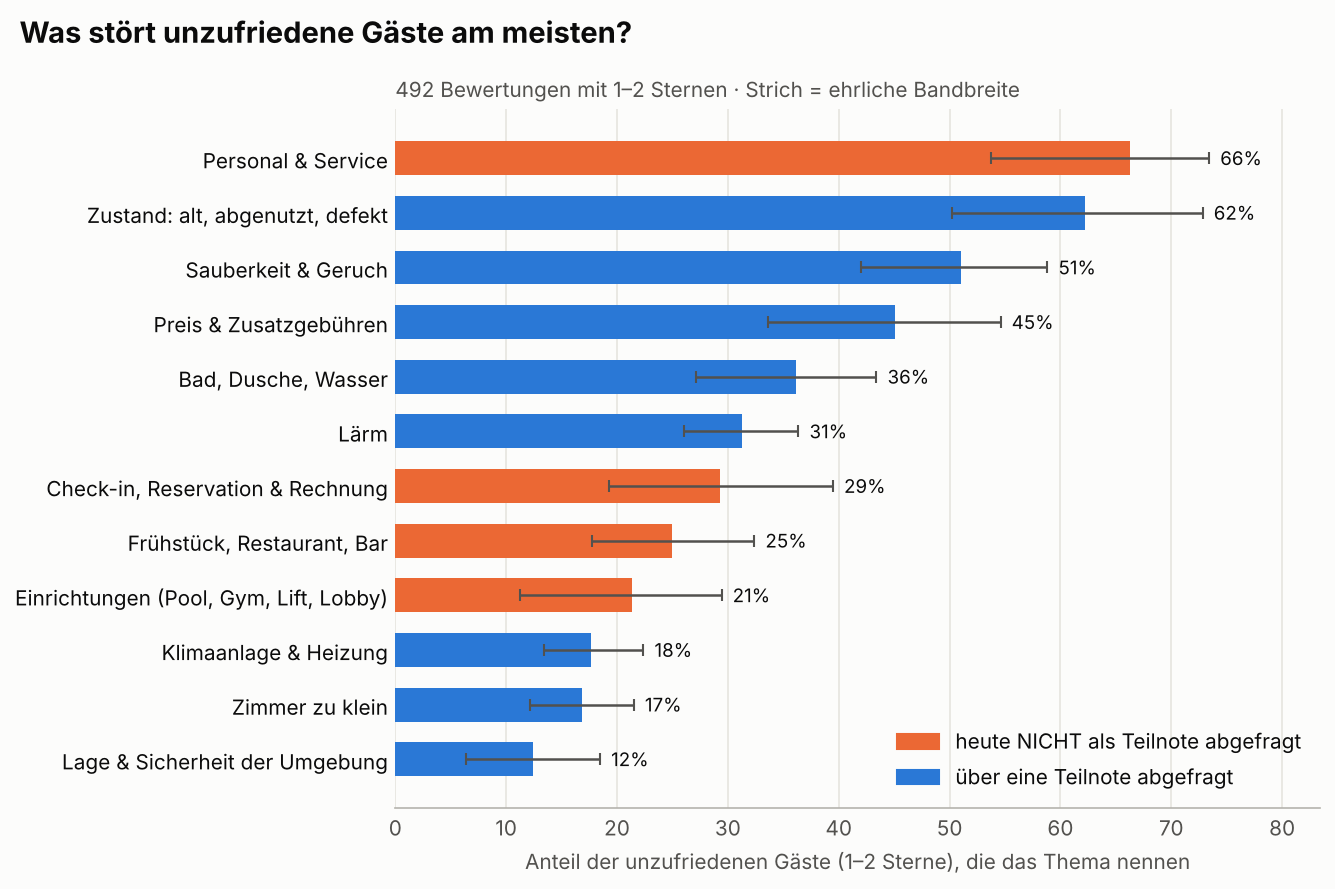

In [19]:
d = d1.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6), dpi=150, facecolor=SURFACE); style(ax)
yy = np.arange(len(d))
ax.barh(yy, d.anteil_unzufrieden * 100, height=0.62,
        color=[ORANGE if t.startswith("-") else BLUE for t in d.Teilnote])
ax.errorbar(d.anteil_unzufrieden * 100, yy,
            xerr=[(d.anteil_unzufrieden - d.von) * 100, (d.bis - d.anteil_unzufrieden) * 100],
            fmt="none", ecolor=INK2, elinewidth=1.2, capsize=3)
for yi, (v, hi) in enumerate(zip(d.anteil_unzufrieden, d.bis)):
    ax.text(hi * 100 + 1, yi, f"{v*100:.0f}%", va="center", color=INK, fontsize=9)
ax.set_yticks(yy, d.Thema, color=INK, fontsize=10)
ax.set_xlim(0, d.bis.max() * 100 + 10)
ax.set_xlabel("Anteil der unzufriedenen Gäste (1–2 Sterne), die das Thema nennen", color=INK2)
fig.suptitle("Was stört unzufriedene Gäste am meisten?", x=0.02, ha="left", fontsize=14, color=INK, weight="bold")
ax.set_title(f"{len(unhappy)} Bewertungen mit 1–2 Sternen · Strich = ehrliche Bandbreite", loc="left", color=INK2, fontsize=10)
ax.legend(handles=LEGENDE, loc="lower right", frameon=False, labelcolor=INK)
fig.tight_layout(); fig.savefig("grafik1_themen_unzufriedene.png", facecolor=SURFACE); plt.show()

**Erkenntnis:** Zwei von drei unzufriedenen Gästen beklagen sich über **Personal & Service**. Das ist das häufigste Thema, und es wird heute nicht abgefragt. Danach folgen Zustand der Zimmer und Sauberkeit.
Ein Coaching wirkt vor allem auf Verhalten und Abläufe (Service, Housekeeping, Beschwerdemanagement), weniger auf alte Bausubstanz.

## 8 · Entscheid 2: Fragen wir die richtigen Teilnoten ab?

Regression: `overall ~ 5 Teilnoten (+ 16 Themen)`.
Der Koeffizient eines Themas sagt: So viele Sterne weniger gibt ein Gast, wenn er das Thema erwähnt, **bei gleichen Teilnoten**. Das ist also das, was die Teilnoten übersehen.
Robuste Standardfehler (HC3). Das ist ein Zusammenhang, keine bewiesene Ursache.

In [20]:
dd = df.copy()
for t in TOPICS:
    dd[t + "_j"] = (dd[t] >= .5).astype(int)
f_a = "overall ~ " + " + ".join("note_" + c for c in SUBS)
f_b = f_a + " + " + " + ".join(t + "_j" for t in TOPICS)
ma = smf.ols(f_a, dd).fit()
mb = smf.ols(f_b, dd).fit(cov_type="HC3")
print(f"Erklärte Varianz R²: nur Teilnoten {ma.rsquared:.3f} → mit Themen {mb.rsquared:.3f}")
ci = mb.conf_int()
d2 = pd.DataFrame([dict(Thema=LABEL[t], Teilnote=SUB_DE.get(SUBSCORE[t], "- (nicht abgefragt)"),
                        abgefragt=SUBSCORE[t] is not None, sterne_effekt=mb.params[t + "_j"],
                        von=ci.loc[t + "_j", 0], bis=ci.loc[t + "_j", 1], p_wert=mb.pvalues[t + "_j"],
                        anteil_alle=dd[t + "_j"].mean()) for t in TOPICS]).sort_values("sterne_effekt")
d2.round(3)

Erklärte Varianz R²: nur Teilnoten 0.781 → mit Themen 0.804


,Thema,Teilnote,abgefragt,sterne_effekt,von,bis,p_wert,anteil_alle
3,Ungeziefer (Bettwanzen etc.),Sauberkeit,True,-0.401,-0.615,-0.188,0.000,0.009
0,Personal & Service,- (nicht abgefragt),False,-0.385,-0.444,-0.326,0.000,0.161
4,"Zustand: alt, abgenutzt, defekt",Zimmer,True,-0.161,-0.214,-0.108,0.000,0.174
15,"Einrichtungen (Pool, Gym, Lift, Lobby)",- (nicht abgefragt),False,-0.112,-0.167,-0.057,0.000,0.092
14,Lage & Sicherheit der Umgebung,Lage,True,-0.088,-0.166,-0.011,0.025,0.053
1,"Check-in, Reservation & Rechnung",- (nicht abgefragt),False,-0.070,-0.142,0.002,0.058,0.078
6,"Bad, Dusche, Wasser",Zimmer,True,-0.061,-0.112,-0.010,0.019,0.118
12,WLAN & Internet,- (nicht abgefragt),False,-0.053,-0.118,0.011,0.106,0.057
13,Parkieren & Valet,- (nicht abgefragt),False,-0.047,-0.113,0.018,0.158,0.062
8,Lärm,Schlaf,True,-0.045,-0.094,0.004,0.069,0.135


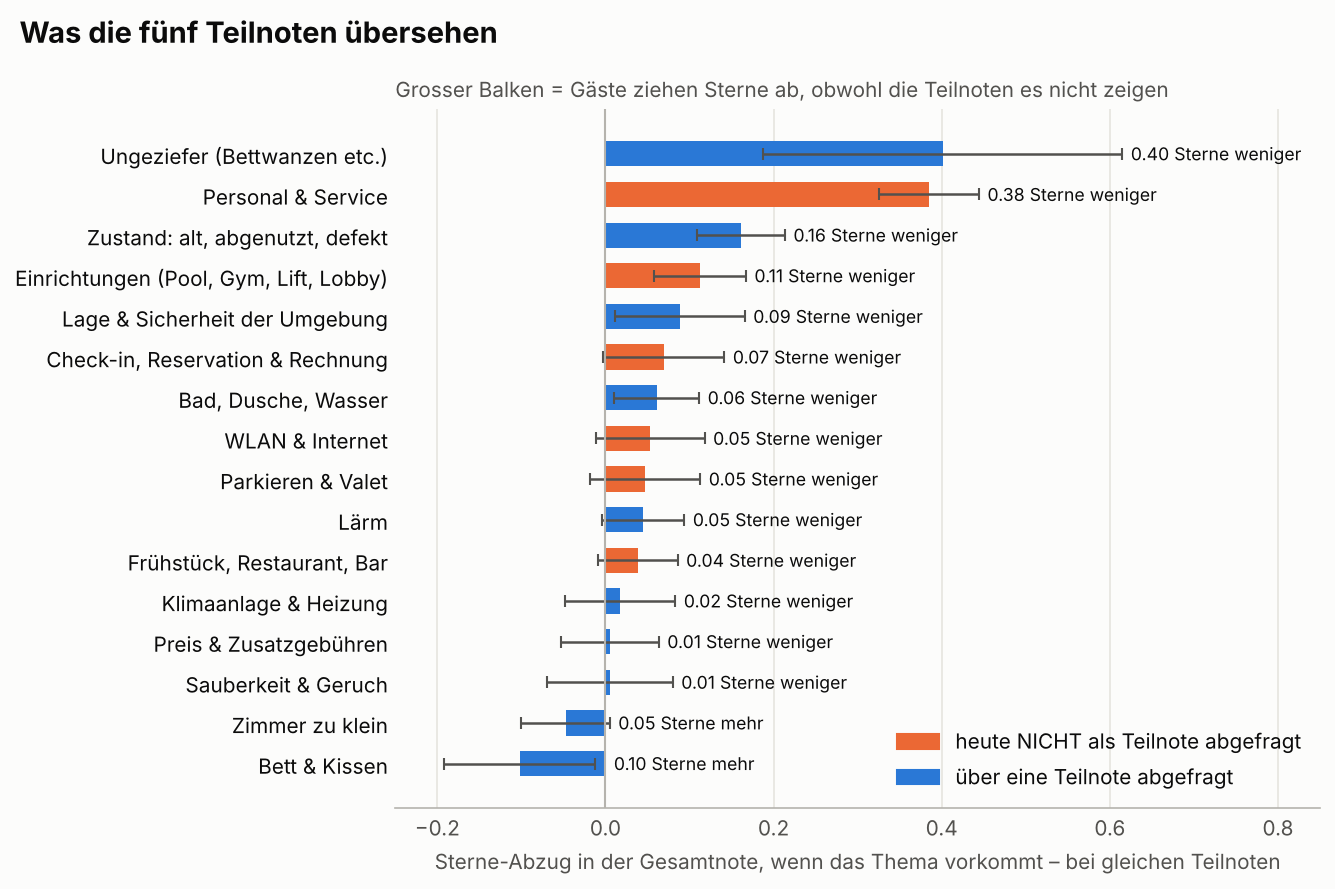

In [21]:
d = d2.sort_values("sterne_effekt", ascending=False)
fig, ax = plt.subplots(figsize=(9, 6), dpi=150, facecolor=SURFACE); style(ax)
yy = np.arange(len(d))
ax.barh(yy, -d.sterne_effekt, height=0.62, color=[BLUE if a else ORANGE for a in d.abgefragt])
ax.errorbar(-d.sterne_effekt, yy, xerr=[d.bis - d.sterne_effekt, d.sterne_effekt - d.von],
            fmt="none", ecolor=INK2, elinewidth=1.2, capsize=3)
for yi, (v, lo) in enumerate(zip(d.sterne_effekt, d.von)):
    ax.text(max(-lo, 0) + 0.01, yi, f"{-v:.2f} Sterne weniger" if v < 0 else f"{v:.2f} Sterne mehr",
            va="center", color=INK, fontsize=8.5)
ax.set_yticks(yy, d.Thema, color=INK, fontsize=10)
ax.axvline(0, color=GREY, lw=1); ax.set_xlim(-0.25, 0.85)
ax.set_xlabel("Sterne-Abzug in der Gesamtnote, wenn das Thema vorkommt – bei gleichen Teilnoten", color=INK2)
fig.suptitle("Was die fünf Teilnoten übersehen", x=0.02, ha="left", fontsize=14, color=INK, weight="bold")
ax.set_title("Grosser Balken = Gäste ziehen Sterne ab, obwohl die Teilnoten es nicht zeigen", loc="left", color=INK2, fontsize=10)
ax.legend(handles=LEGENDE, loc="lower right", frameon=False, labelcolor=INK)
fig.tight_layout(); fig.savefig("grafik2_teilnoten_luecken.png", facecolor=SURFACE); plt.show()

**Erkenntnis:** **Personal & Service** kostet zusätzlich rund 0.4 Sterne und kommt in jeder sechsten Bewertung vor. Das ist die grösste Lücke im heutigen Fragebogen.
Check-in, WLAN, Parkieren und Frühstück haben nur kleine Effekte, die statistisch nicht gesichert sind. Ungeziefer hat einen grossen Effekt, ist aber selten und gehört schon zur Sauberkeit.

## 9 · Entscheid 3: Wie gut erkennt ein KI-Werkzeug Beschwerden?

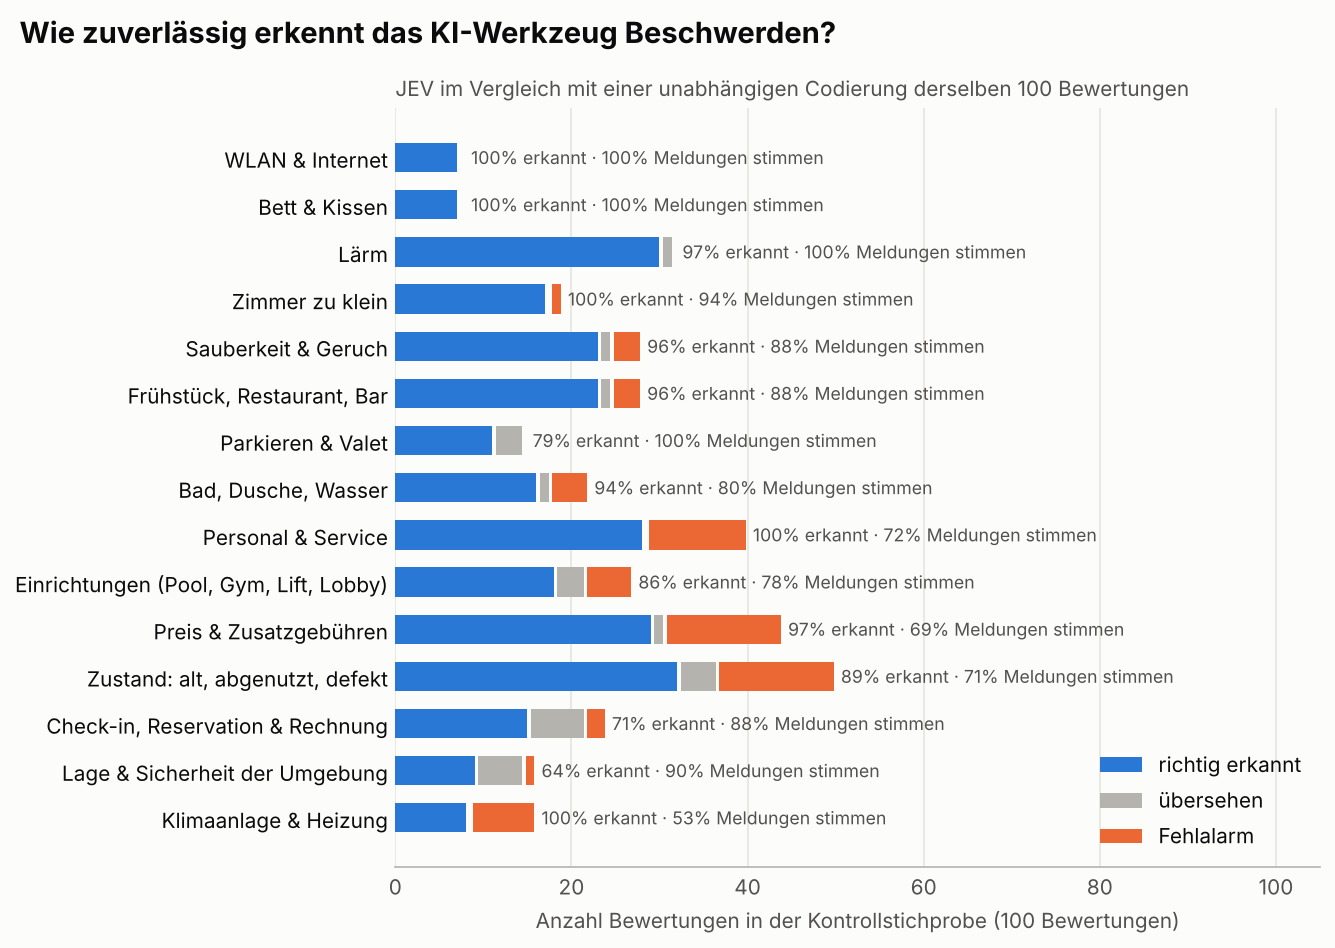

In [22]:
d = d3[(d3.ref_ja >= 7) & (d3.thema != "complaint")].sort_values("jev_f1").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 6.4), dpi=150, facecolor=SURFACE); style(ax)
yy = np.arange(len(d))
ax.barh(yy, d.jev_TP, color=BLUE, height=0.62, label="richtig erkannt")
ax.barh(yy, d.jev_FN, left=d.jev_TP + 0.4, color=GREY, height=0.62, label="übersehen")
ax.barh(yy, d.jev_FP, left=d.jev_TP + d.jev_FN + 0.8, color=ORANGE, height=0.62, label="Fehlalarm")
for yi, r in d.iterrows():
    ax.text(r.jev_TP + r.jev_FN + r.jev_FP + 1.6, yi,
            f"{r.jev_trefferquote*100:.0f}% erkannt · {r.jev_praezision*100:.0f}% Meldungen stimmen",
            va="center", color=INK2, fontsize=8.5)
ax.set_yticks(yy, d.Thema, color=INK, fontsize=10); ax.set_xlim(0, 105)
ax.set_xlabel("Anzahl Bewertungen in der Kontrollstichprobe (100 Bewertungen)", color=INK2)
fig.suptitle("Wie zuverlässig erkennt das KI-Werkzeug Beschwerden?", x=0.02, ha="left", fontsize=14, color=INK, weight="bold")
ax.set_title("JEV im Vergleich mit einer unabhängigen Codierung derselben 100 Bewertungen", loc="left", color=INK2, fontsize=10)
ax.legend(loc="lower right", frameon=False, labelcolor=INK)
fig.tight_layout(); fig.savefig("grafik3_ki_zuverlaessigkeit.png", facecolor=SURFACE); plt.show()

## 10 · Eure Handkontrolle (Pflicht vor der Präsentation)

Die Referenz in Kapitel 5 stammt von einem KI-Werkzeug. Für eine faire Prüfung muss **ein Mensch** mindestens 30 Bewertungen selbst codieren.

1. Die nächste Zelle erstellt `eure_kontrolle.csv` mit den 100 Texten und leeren Spalten.
2. In Excel pro Thema 1 (ja) oder 0 (nein) eintragen, **ohne** vorher die JEV-Resultate anzuschauen.
3. Die übernächste Zelle ausführen.

In [23]:
if not os.path.exists("eure_kontrolle.csv"):
    vorlage = check.sample(frac=1, random_state=7)[["review_id", "title_masked", "text_masked"]].copy()
    for t in THEMES:
        vorlage[t] = ""
    vorlage.to_csv("eure_kontrolle.csv", index=False)
    print("Vorlage erstellt: eure_kontrolle.csv")
else:
    print("eure_kontrolle.csv existiert schon")

Vorlage erstellt: eure_kontrolle.csv


In [24]:
eure = pd.read_csv("eure_kontrolle.csv").dropna(subset=["complaint"])
print(len(eure), "Bewertungen von euch codiert")
if len(eure) >= 10:
    e = eure.set_index("review_id"); r = ref.set_index("review_id"); j = df.set_index("review_id")
    display(pd.DataFrame([dict(Thema=LABEL[t],
                               Übereinstimmung_mit_Referenz=(e[t].astype(int) == r.loc[e.index, t]).mean(),
                               Übereinstimmung_mit_JEV=(e[t].astype(int) == (j.loc[e.index, t] >= .5).astype(int)).mean())
                          for t in THEMES]).round(2))

0 Bewertungen von euch codiert


## 11 · Empfehlungen an die Geschäftsleitung

| Entscheid | Empfehlung |
|---|---|
| **1 Qualitätsbudget** | Den Grossteil der CHF 500'000 in **Service- und Beschwerde-Coaching** stecken (Front Desk, Umgang mit Problemen), den Rest in **Housekeeping-Standards**. Den Zustand der Zimmer separat als Investition prüfen. |
| **2 Teilnoten** | Teilnote **«Personal & Service»** ergänzen. WLAN, Parkieren und Frühstück nicht zusätzlich abfragen. |
| **3 Automatische Auswertung** | **Ja, als Pilot** (3 Monate): nach Thema **und** Sternen weiterleiten, unsichere Fälle (0.3–0.7) an einen Menschen, monatlich 100 Bewertungen von Hand prüfen. Die Zuordnung zum Hotel läuft über die Buchungs-ID, nicht über die KI. |

## 12 · Was die Daten NICHT beantworten können

- **Keine Hotel-Zuordnung:** `hotel_id` ist pro Bewertung eindeutig.
- **2012, USA, Englisch, Tripadvisor:** Die Gäste der Partnerhotels können heute anders sein.
- **Wer schreibt, ist nicht repräsentativ:** Sehr zufriedene und sehr unzufriedene Gäste schreiben häufiger.
- **Zusammenhang ≠ Ursache:** Ob ein Coaching die Noten hebt, zeigt erst ein Pilot mit Vorher-Nachher-Messung.
- **Stichprobe:** 5'000 von 201'295. Seltene Themen sind unsicher.
- **Referenz durch eine KI:** Die Kontrollstichprobe ist bis zu eurer Handkontrolle nicht von Menschen geprüft.

## 13 · Datenschutz und Herkunft

Datensatz: Hugging Face `jniimi/tripadvisor-review-rating` (Apache-2.0, ursprünglich Li et al. 2013, Inhalte von Tripadvisor). Vor dem Versand an JEV wurden `user_id` und `hotel_id` entfernt und Namen, E-Mails und Telefonnummern maskiert.
JEV (TypeSafe, USA) trainiert laut eigener Erklärung nicht mit Kundendaten. Für echte Quartiera-Daten braucht es einen Auftragsverarbeitungsvertrag und eine Prüfung nach nDSG. Der API-Key gehört nie ins Notebook.